In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [43]:
root = "../data"
sp = pd.read_parquet(f"{root}/topic=vehicle_rates_setpoint/flight_id=1/data.parquet")
me = pd.read_parquet(f"{root}/topic=vehicle_angular_velocity/flight_id=1/data.parquet")
st = pd.read_parquet(f"{root}/topic=vehicle_status/flight_id=1/data.parquet")
ns = pd.read_parquet(f"{root}/topic=navigator_status/flight_id=1/data.parquet")
sp.columns, me.columns, st.columns, ns.columns

(Index(['timestamp', 'roll', 'pitch', 'yaw', 'thrust_body[0]', 'thrust_body[1]',
        'thrust_body[2]', 'reset_integral'],
       dtype='str'),
 Index(['timestamp', 'timestamp_sample', 'xyz[0]', 'xyz[1]', 'xyz[2]',
        'xyz_derivative[0]', 'xyz_derivative[1]', 'xyz_derivative[2]'],
       dtype='str'),
 Index(['timestamp', 'armed_time', 'takeoff_time', 'nav_state_timestamp',
        'valid_nav_states_mask', 'can_set_nav_states_mask',
        'failure_detector_status', 'arming_state', 'latest_arming_reason',
        'latest_disarming_reason', 'nav_state_user_intention', 'nav_state',
        'executor_in_charge', 'hil_state', 'vehicle_type', 'failsafe',
        'failsafe_and_user_took_over', 'failsafe_defer_state',
        'gcs_connection_lost', 'gcs_connection_lost_counter',
        'high_latency_data_link_lost', 'is_vtol', 'is_vtol_tailsitter',
        'in_transition_mode', 'in_transition_to_fw', 'system_type', 'system_id',
        'component_id', 'safety_button_available', 'saf

In [44]:
m = pd.merge_asof(me.sort_values("timestamp"), sp.sort_values("timestamp"),
                  on="timestamp", direction="backward", tolerance=50_000)
m["t_s"] = (m["timestamp"] - m["timestamp"].iloc[0]) / 1e6

In [45]:
t0 = int(m["timestamp"].iloc[0])
ns_t = (ns["timestamp"].astype("int64") - t0) / 1e6

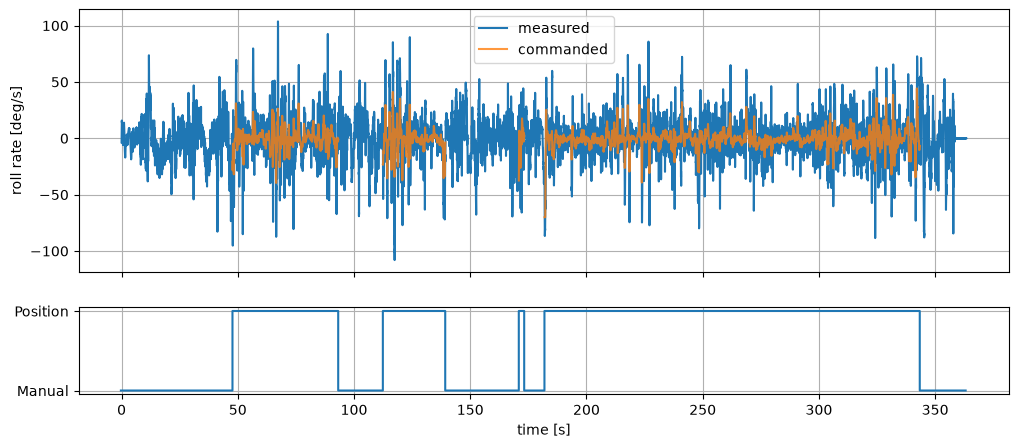

In [50]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 5), sharex=True,
                               gridspec_kw={"height_ratios": [3, 1]})

ax1.plot(m["t_s"], np.degrees(m["xyz[0]"]), label="measured")
ax1.plot(m["t_s"], np.degrees(m["roll"]), label="commanded", alpha=0.8)
ax1.set_ylabel("roll rate [deg/s]"); ax1.grid(True); ax1.legend()

ax2.step(ns_t, ns["nav_state"], where="post")
ax2.set_yticks([0, 2], ["Manual", "Position"])
ax2.set_xlabel("time [s]"); ax2.grid(True)

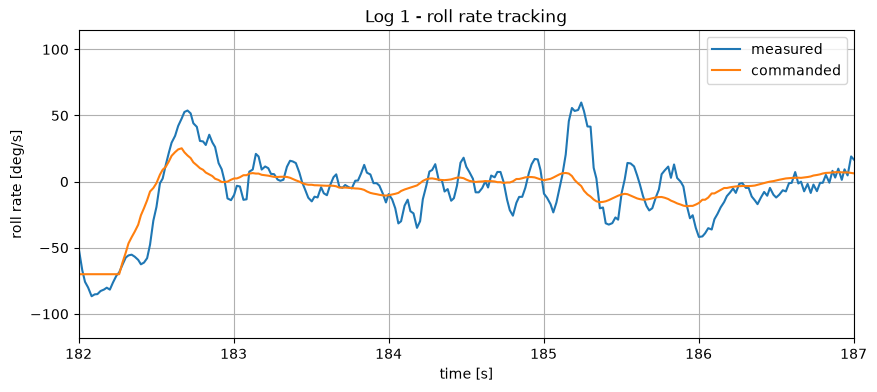

In [55]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(m["t_s"], np.degrees(m["xyz[0]"]), label="measured")
ax.plot(m["t_s"], np.degrees(m["roll"]), label="commanded")
ax.set_xlim(182, 187)
ax.set_xlabel("time [s]"); ax.set_ylabel("roll rate [deg/s]")
ax.set_title("Log 1 - roll rate tracking")
ax.grid(True); ax.legend()
fig.savefig("../roll_rate_tracking.png", dpi=150, bbox_inches="tight")